In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from scipy import interpolate
import scipy.integrate as integrate

import sympy
x =sympy.Symbol('x') ## declare analytical varibles
sympy.init_printing() ## Use LaTeX to print sympy obejects

import sympy as sp


In [ ]:
# actividad 1
A = sp.Matrix([
    [1,  1, -1,  0],
    [6, -4,  0, 24],
    [-6, 0, -2, -10]
])

print("Matriz inicial:")
display(A)
A[1, :] = A[1, :] - 6*A[0, :]
A[2, :] = A[2, :] + 6*A[0, :]
A[1, :] = (-1/10)*A[1, :]
A[2, :] = A[2, :] - 6*A[1, :]
A[2, :] = (-5/22)*A[2, :]
A[1, :] = A[1, :] + (3/5)*A[2, :]
A[0, :] = A[0, :] + A[2, :]
A[0, :] = A[0, :] - A[1, :]

print("Matriz final (forma reducida):")
display(A)

print("Solución del sistema:")
print("x =", A[0,3])
print("y =", A[1,3])
print("z =", A[2,3])


Matriz inicial:


⎡1   1   -1   0 ⎤
⎢               ⎥
⎢6   -4  0   24 ⎥
⎢               ⎥
⎣-6  0   -2  -10⎦

Matriz final (forma reducida):


⎡1   0   1.11022302462516e-16   2.0 ⎤
⎢                                   ⎥
⎢0  1.0  -2.22044604925031e-16  -3.0⎥
⎢                                   ⎥
⎣0   0            1.0           -1.0⎦

Solución del sistema:
x = 2.00000000000000
y = -3.00000000000000
z = -1.00000000000000


n = 5, tiempo promedio = 0.000101 s
n = 10, tiempo promedio = 0.000369 s
n = 50, tiempo promedio = 0.006268 s
n = 100, tiempo promedio = 0.020224 s
n = 500, tiempo promedio = 0.653655 s


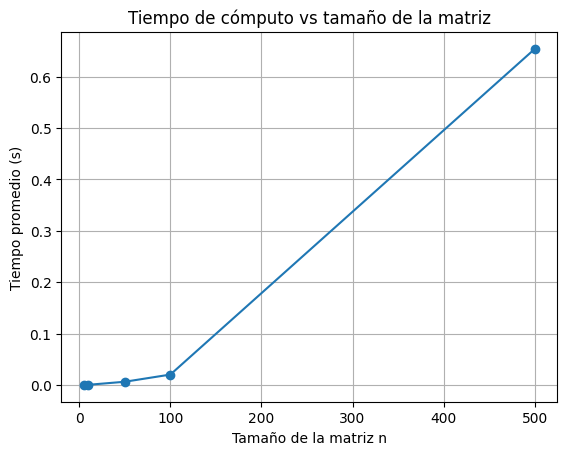

In [ ]:
#actividad 2
import time

# Eliminación Gaussiana sin pivoteo
def Gaussian_Elimination(A, b):
    A = A.astype(float)
    b = b.astype(float)
    n = len(b)
    for k in range(n-1):
        for i in range(k+1, n):
            factor = A[i,k] / A[k,k]
            A[i,k:] = A[i,k:] - factor * A[k,k:]
            b[i] = b[i] - factor * b[k]

    x = np.zeros(n)
    for i in range(n-1, -1, -1):
        x[i] = (b[i] - np.dot(A[i,i+1:], x[i+1:])) / A[i,i]

    return x
# Tamaños de matriz
n_values = [5, 10, 50, 100, 500]
num_runs = 500
times = []

for n in n_values:
    start = time.time()

    for _ in range(num_runs):
        A = np.random.rand(n, n)
        b = np.random.rand(n)
        Gaussian_Elimination(A, b)

    end = time.time()
    avg_time = (end - start) / num_runs
    times.append(avg_time)
    print(f"n = {n}, tiempo promedio = {avg_time:.6f} s")

plt.figure()
plt.plot(n_values, times, marker='o')
plt.xlabel("Tamaño de la matriz n")
plt.ylabel("Tiempo promedio (s)")
plt.title("Tiempo de cómputo vs tamaño de la matriz")
plt.grid(True)
plt.show()


In [ ]:
#actividad 3
def Inverse(A):
    A = A.astype(float)
    n = A.shape[0]
    I = np.eye(n)
    AI = np.hstack((A, I))

    # Eliminación Gauss-Jordan con pivoteo parcial
    for k in range(n):
        # Pivoteo parcial
        max_row = np.argmax(np.abs(AI[k:, k])) + k
        if AI[max_row, k] == 0:
            raise ValueError("La matriz no es invertible")

        AI[[k, max_row]] = AI[[max_row, k]]

        # Normalizar fila pivote
        AI[k] = AI[k] / AI[k, k]

        # Eliminar otras filas
        for i in range(n):
            if i != k:
                factor = AI[i, k]
                AI[i] = AI[i] - factor * AI[k]

    # Extraer la inversa
    A_inv = AI[:, n:]
    return A_inv
A = np.array([[2, 1],
              [5, 3]])
A_inv = Inverse(A)
print("A:")
print(A)
print("\nA inversa:")
print(A_inv)
print("\nA * A_inv:")
print(A @ A_inv)

A:
[[2 1]
 [5 3]]

A inversa:
[[ 3. -1.]
 [-5.  2.]]

A * A_inv:
[[ 1.0000000e+00  0.0000000e+00]
 [-8.8817842e-16  1.0000000e+00]]


n = 1, tiempo = 0.000020 s
n = 2, tiempo = 0.000006 s
n = 3, tiempo = 0.000081 s
n = 4, tiempo = 0.000246 s
n = 5, tiempo = 0.000861 s
n = 6, tiempo = 0.004995 s
n = 7, tiempo = 0.035037 s
n = 8, tiempo = 0.374917 s
n = 9, tiempo = 2.981302 s
n = 10, tiempo = 28.762477 s


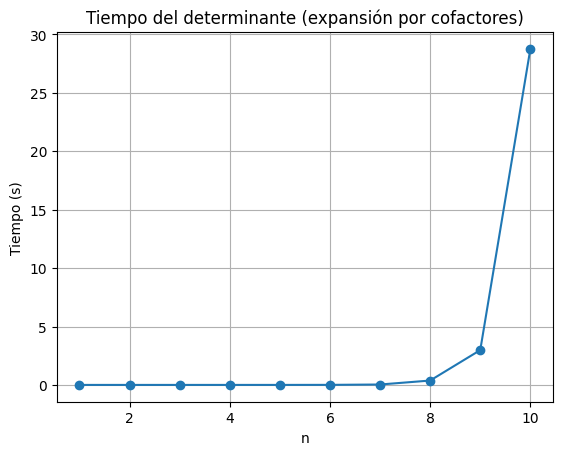

In [ ]:
#actividad 4

# Determinante por expansión de cofactores
def Determinant(A):
    n = A.shape[0]
    if n == 1:
        return A[0, 0]
    if n == 2:
        return A[0,0]*A[1,1] - A[0,1]*A[1,0]
    det = 0
    for j in range(n):
        minor = np.delete(np.delete(A, 0, axis=0), j, axis=1)
        det += ((-1)**j) * A[0, j] * Determinant(minor)

    return det
# Tamaños
n_values = range(1, 11)
repeats = 5
times = []

for n in n_values:
    start = time.time()
    for _ in range(repeats):
        A = np.random.rand(n, n)
        Determinant(A)
    end = time.time()

    avg_time = (end - start) / repeats
    times.append(avg_time)
    print(f"n = {n}, tiempo = {avg_time:.6f} s")

plt.plot(n_values, times, marker='o')
plt.xlabel("n")
plt.ylabel("Tiempo (s)")
plt.title("Tiempo del determinante (expansión por cofactores)")
plt.grid()
plt.show()


n = 1, tiempo = 0.000033 s
n = 2, tiempo = 0.000046 s
n = 3, tiempo = 0.000116 s
n = 4, tiempo = 0.000099 s
n = 5, tiempo = 0.000092 s
n = 6, tiempo = 0.000102 s
n = 7, tiempo = 0.000131 s
n = 8, tiempo = 0.000157 s
n = 9, tiempo = 0.000197 s
n = 10, tiempo = 0.000232 s


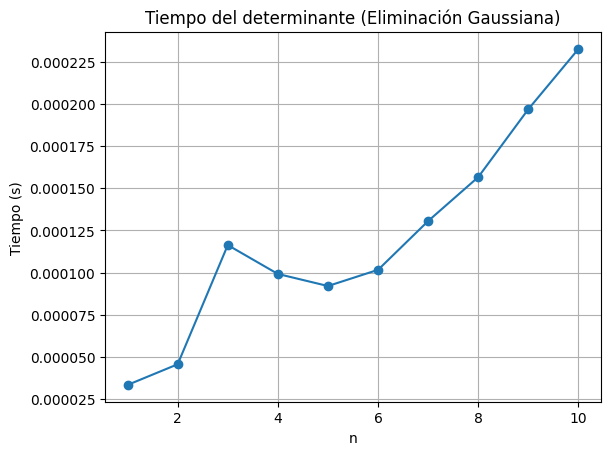

In [ ]:
#actividad 5
def Gaussian_Determinant(A):
    A = A.astype(float)
    n = A.shape[0]
    det = 1

    for k in range(n):
        # Pivoteo parcial
        max_row = np.argmax(np.abs(A[k:, k])) + k
        if A[max_row, k] == 0:
            return 0

        if max_row != k:
            A[[k, max_row]] = A[[max_row, k]]
            det *= -1

        det *= A[k, k]

        for i in range(k+1, n):
            factor = A[i, k] / A[k, k]
            A[i, k:] -= factor * A[k, k:]

    return det


# Tamaños
n_values = range(1, 11)
repeats = 20
times = []

for n in n_values:
    start = time.time()
    for _ in range(repeats):
        A = np.random.rand(n, n)
        Gaussian_Determinant(A.copy())
    end = time.time()

    avg_time = (end - start) / repeats
    times.append(avg_time)
    print(f"n = {n}, tiempo = {avg_time:.6f} s")

# Gráfica
plt.plot(n_values, times, marker='o')
plt.xlabel("n")
plt.ylabel("Tiempo (s)")
plt.title("Tiempo del determinante (Eliminación Gaussiana)")
plt.grid()
plt.show()
